Dmitri Gomon, i.d. 304442353

## Deep Learning 22961
## Maman 13

In [195]:
import csv
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import torch
from matplotlib.ticker import MaxNLocator
from torch import nn, Tensor
from torch.optim import Optimizer
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

filename = "diabetes.csv"

def load_data(path: str | Path) -> list[list[str]]:
    with open(path, newline='') as csvfile:
        return list(csv.reader(csvfile, delimiter = '\t'))


def find_decile_index(decile: int, decile_ranges: list[list[int]]) -> int:
    for i in range(len(decile_ranges)):
        if decile_ranges[i][0] <= int(decile) <= decile_ranges[i][1]:
            return i
    return 0


def train_model(model: nn.Module, optimizer: Optimizer, dataloader: DataLoader,
                target_acc: float, ignore_y: bool) -> tuple[int, float | int]:
    epochs = 0
    epoch_acc = 0
    loss_fn = nn.NLLLoss()

    while epoch_acc < target_acc:
        epochs += 1
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        # run full epoch
        for features, labels in dataloader:
            optimizer.zero_grad()
            y_model = model(features) if not ignore_y else model(features[:, :-1])
            loss = loss_fn(y_model, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            predicted_labels = torch.argmax(y_model, dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            total_samples += batch_size

        epoch_acc = correct_predictions / total_samples

    return epochs, epoch_acc


def evaluate_model(model, dataloader, ignore_y: bool) -> float:
    correct_predictions = 0
    total_samples = 0

    for features, labels in dataloader:
        batch_size = labels.size(0)
        y_model = model(features) if not ignore_y else model(features[:, :-1])
        predicted_labels = torch.argmax(y_model, dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        total_samples += batch_size

    return correct_predictions / total_samples

def run_epoch(model: nn.Module, dataloader: DataLoader, loss_fn: nn.Module, step: bool,
              optimizer: torch.optim.Optimizer) -> float:
    running_loss = 0.0
    total_samples = 0
    grad_ctx = nullcontext() if step else torch.no_grad()

    with grad_ctx:
        for features, targets in dataloader:
            preds = model(features).squeeze(-1)
            targets = targets.float().squeeze(-1)
            loss = loss_fn(preds, targets)

            if step:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

    return running_loss / total_samples


def show_graph(history: list[tuple[float, float]]) -> None:
    epochs_range = range(1, len(history) + 1)
    e_in_vals = [pair[0] for pair in history]
    e_val_vals = [pair[1] for pair in history]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs_range, e_in_vals, marker="o", label="Train MSE (E_in)")
    ax.plot(epochs_range, e_val_vals, marker="s", label="Validation MSE (E_val)")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=10))
    ax.set_title("Training and Validation MSE over Epochs")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
    fig.tight_layout()
    plt.show()

## 3.

In [196]:
def calc_ranges(data: list[list[str]], num: int):
    # read y_values (still as strings) from all rows
    y_values = [row[-1] for row in data if row]
    # convert y values to ints
    y_values = [int(y) for y in y_values]
    cutoffs = np.percentile(y_values, np.linspace(0, 100, num))
    # Consecutive pairs (low, high) form the ranges
    return list(zip(cutoffs[:-1], cutoffs[1:]))

train_data = load_data(filename)
decile_ranges = calc_ranges(train_data[1:], 11)

## 4.

In [197]:
def add_class_col(data, decile_ranges):
    data[0].append("Class")
    for row in data[1:]:
        decile_index = find_decile_index(row[-1], decile_ranges)
        row.append(decile_index)    # 0-based decile labels [0..9]

add_class_col(train_data, decile_ranges)

## 5.

In [198]:
class DiabetesDataset(Dataset):
    def __init__(self, rows: list[list]) -> None:
        """
        rows: data rows excluding the header row (e.g., data_loader.data[1:]).
        """

        # row[:-1] contains the feature values; row[-1] is the class label
        raw_features = torch.tensor(
            [[float(val) for val in row[:-1]] for row in rows],
            dtype=torch.float32,
        )

        # normalize data
        mean = raw_features.mean(dim=0, keepdim=True)
        std = raw_features.std(dim=0, keepdim=True, unbiased=False)
        std = torch.where(std == 0, torch.ones_like(std), std)

        self.features = (raw_features - mean) / std

        self.targets = torch.tensor(
            [int(row[-1]) for row in rows],
            dtype=torch.long,
        )

    def __len__(self) -> int:
        return self.features.size(0)

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        return self.features[index], self.targets[index]

diabetes_dataset = DiabetesDataset(train_data[1:])

## 6.

In [199]:
dataloader = DataLoader(diabetes_dataset,  batch_size=10, shuffle=False)

## 7.

In [200]:
features, targets = next(iter(dataloader))
print("features:", features)
print("targets", targets)

features: tensor([[ 0.8005,  1.0655,  1.2971,  0.4598, -0.9297, -0.7321, -0.9125, -0.0545,
          0.4185, -0.3710, -0.0147],
        [-0.0396, -0.9385, -1.0822, -0.5535, -0.1776, -0.4029,  1.5644, -0.8303,
         -1.4366, -1.9385, -1.0017],
        [ 1.7933,  1.0655,  0.9345, -0.1192, -0.9587, -0.7189, -0.6802, -0.0545,
          0.0602, -0.5452, -0.1446],
        [-1.8724, -0.9385, -0.2438, -0.7707,  0.2563,  0.5254, -0.7576,  0.7213,
          0.4770, -0.1968,  0.6995],
        [ 0.1132, -0.9385, -0.7649,  0.4598,  0.0827,  0.3279,  0.1712, -0.0545,
         -0.6725, -0.9806, -0.2225],
        [-1.9488, -0.9385, -0.8556, -0.4087, -1.4504, -1.6669,  0.8678, -1.6061,
         -0.8657, -2.0256, -0.7160],
        [-0.9560,  1.0655, -0.9915, -0.3364, -0.8430, -0.5214,  0.0164, -0.8303,
         -1.3228, -0.8064, -0.1835],
        [ 1.3351,  1.0655, -0.0398,  1.4008,  1.9052,  2.2898,  0.4808,  0.3722,
         -0.7530,  0.0644, -1.1575],
        [ 0.8769,  1.0655,  1.2971, -0.8430, -

## 8.

In [201]:
dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=False)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.1, ignore_y=False)

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_in={acc_in_a:.4f}")

[model_a | ignore_y=False] epochs=5 |  acc_in=0.1018


## 9.

In [202]:
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=False)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.1, ignore_y=True)
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_in={acc_in_b:.4f}")



[model_b | ignore_y=True] epochs=3 |  acc_in=0.1176


## 10.

In [203]:
# 10
train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=False)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=False)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 10),
    nn.LogSoftmax(dim=1),
)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0
for i in range(n_runs):
    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.1, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.1, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print("acc_out_a: ", acc_out_a)
print("acc_out_b: ", acc_out_b)


acc_out_a:  0.38431818181818195
acc_out_b:  0.22011363636363643


## 11

In [204]:
train_data = load_data(filename)
percentile_ranges = calc_ranges(train_data[1:], num = 101)
add_class_col(train_data, percentile_ranges)

## 13.8

In [205]:
diabetes_dataset = DiabetesDataset(train_data[1:])
dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=False)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.005, ignore_y=False)
print("epochs_a: ", epochs_a, " acc_in_a: ", acc_in_a)

epochs_a:  7  acc_in_a:  0.006787330316742082


## 13.9

In [206]:
diabetes_dataset = DiabetesDataset(train_data[1:])
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=False)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.005, ignore_y=True)
print("epochs_b: ", epochs_b, " acc_in_b: ", acc_in_b)

epochs_b:  1  acc_in_b:  0.013574660633484163


## 13.10

In [207]:
train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=False)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=False)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 100),
    nn.LogSoftmax(dim=1),
)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0

for i in range(n_runs):
    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.005, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.001, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print("acc_out_a: ", acc_out_a)
print("acc_out_b: ", acc_out_b)


acc_out_a:  0.02420454545454547
acc_out_b:  0.0


## 14.

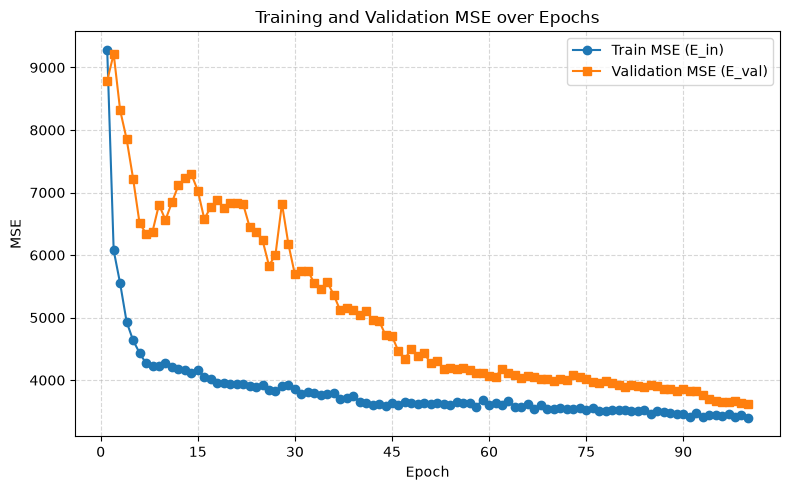

In [208]:
train_data = load_data(filename)
diabetes_dataset = DiabetesDataset(train_data[1:])

train_ds, val_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=False)
val_dataloader = DataLoader(val_ds,  batch_size=10, shuffle=False)

model = nn.Sequential(
    nn.Linear(10, 5),
    nn.ReLU(),
    nn.Linear(5, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=0.002)

n_epochs = 100
loss_fn = nn.MSELoss()
history: list[tuple[float, float]] = []

for epoch in range(n_epochs):
    e_in = run_epoch(model, train_dataloader, loss_fn, True, optimizer)
    e_val = run_epoch(model, val_dataloader, loss_fn, False, None)
    history.append((e_in, e_val))

show_graph(history)
